In [1]:
import numpy as np 
import pandas as pd

In [ ]:
import h5py
import numpy as np

FILE_PATH = "/Users/kyu/Downloads/broadband_data_20260411_173455.h5"

with h5py.File(FILE_PATH, "r") as f:
    raw = f["acquisition/ElectricalSeries"][:]
    t_ns = f["acquisition/timestamp_ns"][:]  # optional, can ignore

n_time = len(t_ns)
n_ch = len(raw) // n_time

data = raw.reshape(n_time, n_ch)   # no timestamp here

X_signal = data[:, :-12]
X_aux = data[:, -12:]

fs = 31000

print("signal shape:", X_signal.shape)
print("aux shape:", X_aux.shape)

signal shape: (4850176, 64)
aux shape: (4850176, 12)


# neural process

In [8]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.signal import welch, iirnotch, filtfilt

def auto_notch_filter_with_plot(
    data,
    fs=1000,
    search_band=(55, 65),
    Q=30.0,
    num_channels=3,
    seed=None,
    xlim=(0, 200),
):
    """
    Detect the strongest narrowband noise peak in `search_band`,
    apply a notch filter there across all channels,
    and plot Welch PSD before/after for a few channels.

    Parameters
    ----------
    data : pd.DataFrame or np.ndarray
        Time x Channels
    fs : float
        Sampling rate in Hz
    search_band : tuple
        Frequency band in which to search for line noise peak
    Q : float
        Notch quality factor
    num_channels : int
        Number of channels to plot
    seed : int or None
        Random seed for channel selection
    xlim : tuple
        Frequency axis limits for PSD plots

    Returns
    -------
    filtered_data : np.ndarray
        Time x Channels filtered array
    notch_freq : float
        Detected notch frequency
    """

    # convert to DataFrame, preserving Time x Channels
    if isinstance(data, np.ndarray):
        data = pd.DataFrame(data, columns=[f"ch_{i}" for i in range(data.shape[1])])
    elif not isinstance(data, pd.DataFrame):
        raise TypeError("data must be a pandas DataFrame or a numpy array")

    rng = np.random.default_rng(seed)

    channel_names = data.columns.to_list()
    selected_channels = rng.choice(
        channel_names,
        size=min(num_channels, len(channel_names)),
        replace=False
    )

    # average across channels to detect shared line noise
    avg_signal = data.mean(axis=1).to_numpy()

    nperseg = min(len(avg_signal), int(fs * 2))
    f, Pxx = welch(avg_signal, fs=fs, nperseg=nperseg)

    mask = (f >= search_band[0]) & (f <= search_band[1])
    if not np.any(mask):
        raise ValueError("search_band does not overlap Welch frequencies")

    notch_freq = f[mask][np.argmax(Pxx[mask])]
    print(f"Detected notch frequency: {notch_freq:.2f} Hz")

    # design and apply notch across all channels
    b, a = iirnotch(notch_freq, Q, fs)
    filtered_array = filtfilt(b, a, data.to_numpy(), axis=0)
    filtered_data = pd.DataFrame(filtered_array, columns=data.columns, index=data.index)

    # plot before/after PSD
    fig, axes = plt.subplots(1, 2, figsize=(14, 4), sharey=True)

    for ch in selected_channels:
        x_raw = data[ch].to_numpy()
        x_filt = filtered_data[ch].to_numpy()

        f_raw, P_raw = welch(x_raw, fs=fs, nperseg=min(len(x_raw), int(fs * 2)))
        f_filt, P_filt = welch(x_filt, fs=fs, nperseg=min(len(x_filt), int(fs * 2)))

        axes[0].plot(f_raw, 10 * np.log10(P_raw + 1e-12), label=str(ch))
        axes[1].plot(f_filt, 10 * np.log10(P_filt + 1e-12), label=str(ch))

    for ax in axes:
        ax.axvspan(search_band[0], search_band[1], color="gray", alpha=0.2)
        ax.axvline(notch_freq, linestyle="--", alpha=0.7)
        ax.set_xlim(*xlim)
        ax.set_xlabel("Frequency (Hz)")
        ax.set_ylabel("Power (dB/Hz)")
        ax.grid(True, alpha=0.3)

    axes[0].set_title("Before notch")
    axes[1].set_title("After notch")
    axes[1].legend()
    plt.tight_layout()
    plt.show()

    return filtered_data.to_numpy(), notch_freq

Detected notch frequency: 58.00 Hz


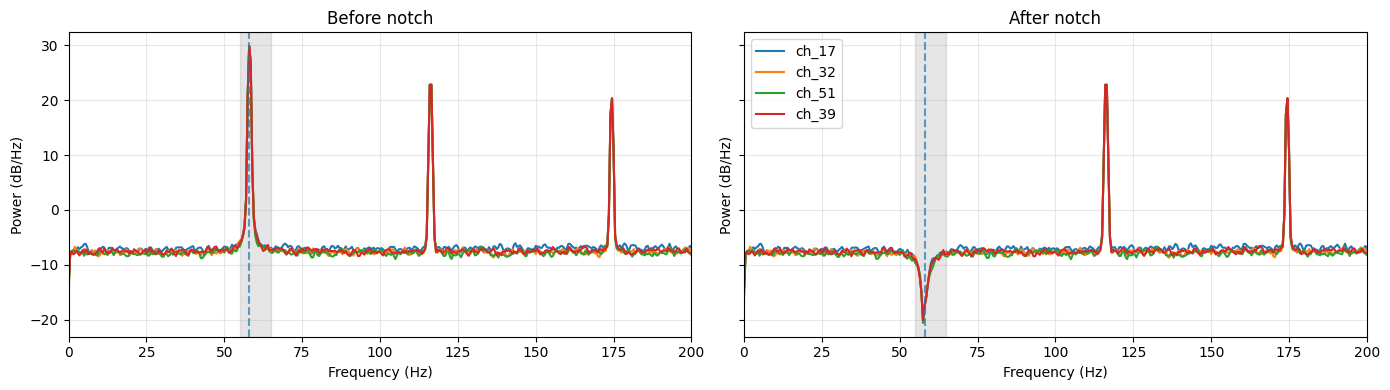

Detected notch frequency: 116.50 Hz


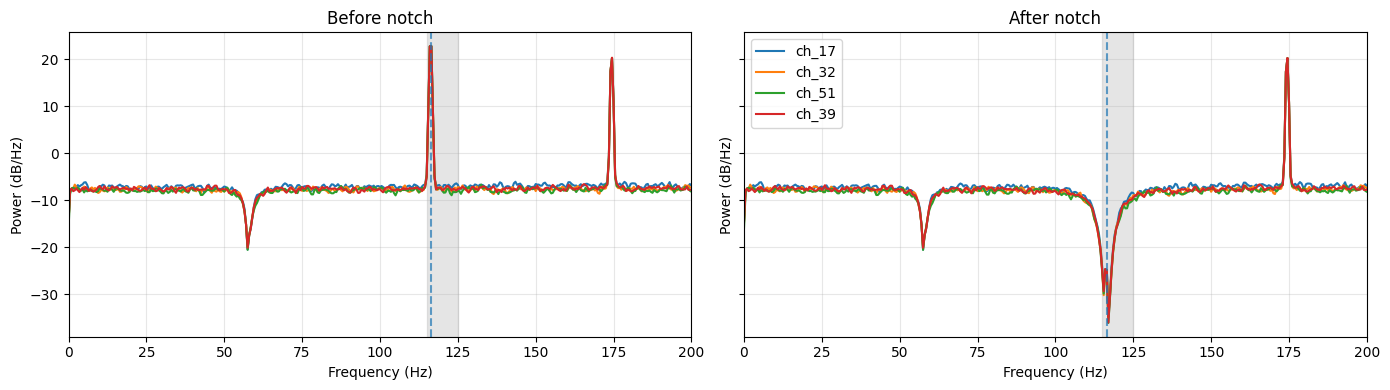

Detected notch frequency: 175.00 Hz


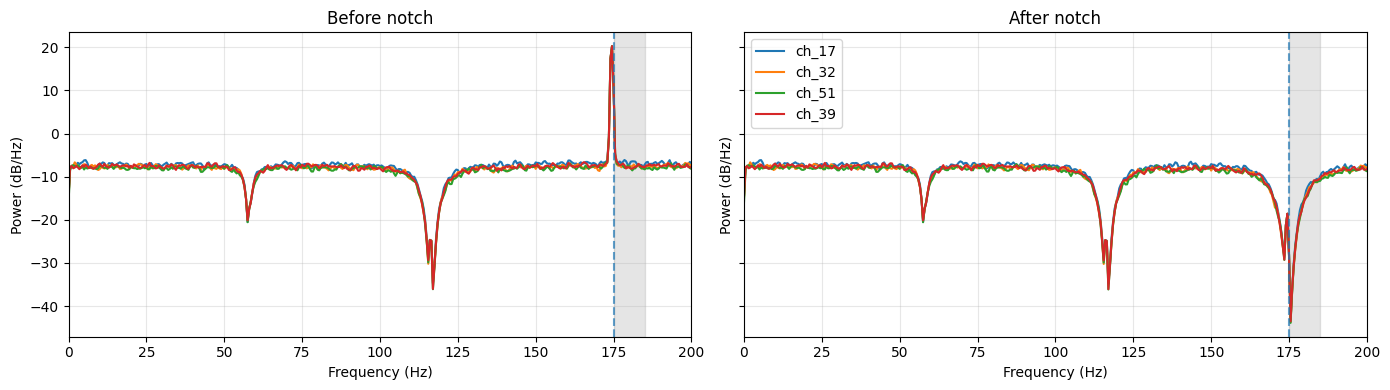

In [39]:
X_notched, notch_freq = auto_notch_filter_with_plot(
    X_signal,
    fs=31000,
    search_band=(55, 65),
    Q=15,
    num_channels=4,
    seed=0
)

X_notched, notch_freq = auto_notch_filter_with_plot(
    X_notched,
    fs=31000,
    search_band=(115, 125),
    Q=15,
    num_channels=4,
    seed=0
)

X_notched, notch_freq = auto_notch_filter_with_plot(
    X_notched,
    fs=31000,
    search_band=(175, 185),
    Q=15,
    num_channels=4,
    seed=0
)

In [133]:
import numpy as np
from importlib import reload
import kyunghwan_spike_functions as s
reload(s)


fs_raw = 31_000
fs_rate = 1000

n_time, n_ch = X_notched.shape
n_time_rate = int(np.floor(n_time * fs_rate / fs_raw))

rate_mat = np.zeros((n_time_rate, n_ch))

for ch in range(n_ch):
    res = s.threshold_and_rate(
        X_signal[:, ch],
        fs_raw=fs_raw,
        fs_rate=fs_rate,
        k=5,
        mode="negative",
        refractory_s=0.001,
        smooth_method="none",
        smooth_sigma_s=0.01   # 10 ms smoothing on 1 kHz timeline
    )
    rate_mat[:, ch] = res["rate"]

print(rate_mat.shape)

(156457, 64)


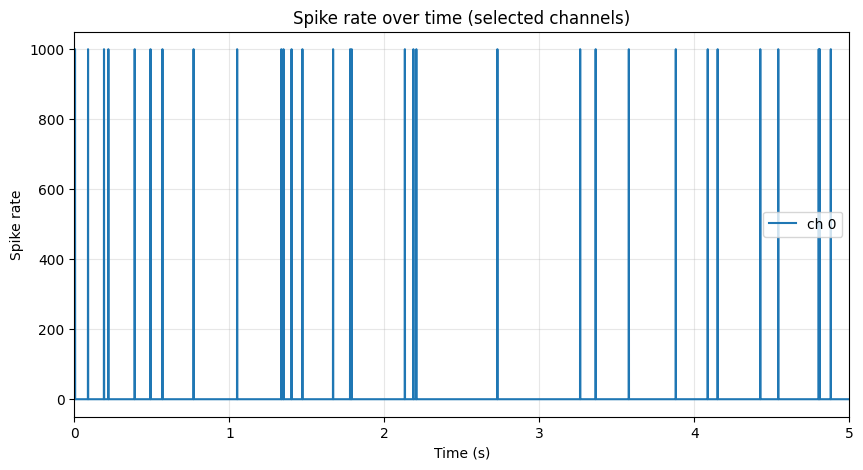

In [134]:
import numpy as np
import matplotlib.pyplot as plt

fs = 1000  # Hz
t = np.arange(rate_mat.shape[0]) / fs  # time in seconds

# choose a few channels
channels_to_plot = [0]  # change as needed

plt.figure(figsize=(10, 5))

for ch in channels_to_plot:
    plt.plot(t, rate_mat[:, ch], label=f'ch {ch}')

plt.xlabel('Time (s)')
plt.ylabel('Spike rate')
plt.xlim((0,5))
plt.title('Spike rate over time (selected channels)')
plt.legend()
plt.grid(alpha=0.3)
plt.show()

# button process

In [135]:
buttons_raw = X_aux[:, 4:]       # shape: (time_raw, 8)
buttons_ds  = X_aux[:, 4:]    # optional, for plotting / alignment later

print("buttons_raw shape:", buttons_raw.shape)
print("buttons_ds shape:", buttons_ds.shape)

def find_button_events_ds(button_data, threshold=None):
    """
    button_data: (time, n_buttons)

    Returns:
        events[ch] = {
            "onsets":  array of onset indices,
            "offsets": array of offset indices,
            "active":  boolean active trace
        }

    If threshold is None, a per-channel threshold is chosen automatically.
    """
    n_time, n_buttons = button_data.shape
    events = {}

    for ch in range(n_buttons):
        x = button_data[:, ch]

        # automatic threshold
        if threshold is None:
            thr = 0.5 * np.max(np.abs(x))
        else:
            thr = threshold

        active = np.abs(x) > thr
        d = np.diff(active.astype(int))

        onsets = np.where(d == 1)[0] + 1
        offsets = np.where(d == -1)[0] + 1

        # handle edge cases
        if active[0]:
            onsets = np.r_[0, onsets]
        if active[-1]:
            offsets = np.r_[offsets, n_time]

        events[ch] = {
            "onsets": onsets,
            "offsets": offsets,
            "active": active,
            "threshold": thr
        }

    return events

events_ds = find_button_events_ds(buttons_ds, threshold=None)

for ch in range(buttons_ds.shape[1]):
    print(
        f"Button {ch}: {len(events_ds[ch]['onsets'])} presses, "
        f"threshold={events_ds[ch]['threshold']:.4f}"
    )

buttons_raw shape: (4850176, 8)
buttons_ds shape: (4850176, 8)
Button 0: 5 presses, threshold=16383.5000
Button 1: 5 presses, threshold=16383.5000
Button 2: 5 presses, threshold=16383.5000
Button 3: 5 presses, threshold=16383.5000
Button 4: 5 presses, threshold=16383.5000
Button 5: 5 presses, threshold=16383.5000
Button 6: 0 presses, threshold=0.0000
Button 7: 0 presses, threshold=0.0000


In [136]:
def extract_event_windows_ds(X, onset_indices, fs, t_pre=0.5, t_post=0.5):
    """
    X: (time, channels)
    onset_indices: onset sample indices
    fs: sampling rate

    Returns:
        windows:    (n_events, win_len, channels)
        kept_onsets
        rel_t:      relative time vector
    """
    n_pre = int(round(t_pre * fs))
    n_post = int(round(t_post * fs))
    win_len = n_pre + n_post

    windows = []
    kept_onsets = []

    for onset in onset_indices:
        start = onset - n_pre
        end = onset + n_post

        if start < 0 or end > X.shape[0]:
            continue

        windows.append(X[start:end, :])
        kept_onsets.append(onset)

    if len(windows) == 0:
        windows = np.empty((0, win_len, X.shape[1]))
        kept_onsets = np.array([], dtype=int)
    else:
        windows = np.stack(windows, axis=0)
        kept_onsets = np.array(kept_onsets, dtype=int)

    rel_t = np.arange(-n_pre, n_post) / fs
    return windows, kept_onsets, rel_t

In [137]:
from scipy.signal import butter, sosfilt

fs_raw = 31000
fs_rate = 1000
down = fs_raw // fs_rate   # 31

# lowpass before decimation (avoid aliasing)
sos = butter(6, 100, btype="low", fs=fs_raw, output="sos")

X_aux_filt = sosfilt(sos, X_aux, axis=0)
X_aux_ds = X_aux_filt[::down]

print("X_aux_1k shape:", X_aux_ds.shape)

X_aux_1k shape: (156458, 12)


In [138]:
# 1. build 1 kHz aux
X_aux_filt = sosfilt(sos, X_aux, axis=0)
X_aux_ds = X_aux_filt[::down]

# 2. align with rate_mat
n_shared = min(rate_mat.shape[0], X_aux_ds.shape[0])
rate_mat = rate_mat[:n_shared]
X_aux_ds = X_aux_ds[:n_shared]

# 3. extract buttons from 1 kHz aux
buttons_ds = X_aux_ds[:, 4:]

print("buttons_ds shape:", buttons_ds.shape)

buttons_ds shape: (156457, 8)


In [139]:
from scipy.signal import butter, sosfilt
import numpy as np

# -----------------------------
# 1) downsample aux to 1 kHz
# -----------------------------
fs_raw = 31000
fs_rate = 1000
down = fs_raw // fs_rate

sos = butter(6, 100, btype="low", fs=fs_raw, output="sos")
X_aux_filt = sosfilt(sos, X_aux, axis=0)
X_aux_ds = X_aux_filt[::down]

# -----------------------------
# 2) align exactly to rate_mat
# -----------------------------
n_shared = min(rate_mat.shape[0], X_aux_ds.shape[0])
rate_mat = rate_mat[:n_shared]
X_aux_ds = X_aux_ds[:n_shared]

# -----------------------------
# 3) rebuild buttons from THIS aux
# -----------------------------
buttons_ds = X_aux_ds[:, 4:]

print("rate_mat shape:", rate_mat.shape)
print("X_aux_ds shape:", X_aux_ds.shape)
print("buttons_ds shape:", buttons_ds.shape)

# -----------------------------
# 4) REDEFINE event detector here
# -----------------------------
def find_button_events_ds(button_data, threshold=None):
    n_time, n_buttons = button_data.shape
    events = {}

    for ch in range(n_buttons):
        x = np.asarray(button_data[:, ch], dtype=float)

        if threshold is None:
            thr = 0.5 * np.max(np.abs(x))
        else:
            thr = float(threshold)

        active = np.abs(x) > thr
        d = np.diff(active.astype(int))

        onsets = np.where(d == 1)[0] + 1
        offsets = np.where(d == -1)[0] + 1

        if active[0]:
            onsets = np.r_[0, onsets]
        if active[-1]:
            offsets = np.r_[offsets, n_time]

        events[ch] = {
            "onsets": onsets,
            "offsets": offsets,
            "active": active,
            "threshold": thr
        }

    return events

# -----------------------------
# 5) rebuild events RIGHT NOW
# -----------------------------
events_ds = find_button_events_ds(buttons_ds, threshold=None)

for ch in range(buttons_ds.shape[1]):
    onsets = events_ds[ch]["onsets"]
    print(f"button {ch}: n_onsets={len(onsets)}")
    if len(onsets) > 0:
        print("  first few onsets:", onsets[:10])
        print("  min/max:", onsets.min(), onsets.max())
        print("  all onsets valid:", np.all(onsets < buttons_ds.shape[0]))

rate_mat shape: (156457, 64)
X_aux_ds shape: (156457, 12)
buttons_ds shape: (156457, 8)
button 0: n_onsets=5
  first few onsets: [4276 5189 6052 6925 7892]
  min/max: 4276 7892
  all onsets valid: True
button 1: n_onsets=5
  first few onsets: [ 9619 10414 11278 12131 12997]
  min/max: 9619 12997
  all onsets valid: True
button 2: n_onsets=5
  first few onsets: [14807 15690 16574 17506 18444]
  min/max: 14807 18444
  all onsets valid: True
button 3: n_onsets=5
  first few onsets: [20279 21085 21950 22883 23941]
  min/max: 20279 23941
  all onsets valid: True
button 4: n_onsets=5
  first few onsets: [33328 34156 35077 35855 36637]
  min/max: 33328 36637
  all onsets valid: True
button 5: n_onsets=5
  first few onsets: [26973 27763 28604 29550 30386]
  min/max: 26973 30386
  all onsets valid: True
button 6: n_onsets=0
button 7: n_onsets=0


In [140]:
t_pre = .1
t_post = 0.1
fs_rate = 1000

# buttons_ds should already be the 1 kHz button channels
# example:
# buttons_ds = X_aux_1k[:, 4:]

button_windows_rate = {}
button_windows_aux = {}

for ch in range(buttons_ds.shape[1]):
    onsets = events_ds[ch]["onsets"]   # these must be on the 1 kHz timeline

    rate_wins, kept_onsets, rel_t = extract_event_windows_ds(
        rate_mat,
        onsets,
        fs=fs_rate,
        t_pre=t_pre,
        t_post=t_post
    )

    aux_wins, _, _ = extract_event_windows_ds(
        X_aux_ds,   # or X_aux_1k, whichever is your 1 kHz aux array
        onsets,
        fs=fs_rate,
        t_pre=t_pre,
        t_post=t_post
    )

    button_windows_rate[ch] = {
        "windows": rate_wins,   # (n_events, win_len, n_rate_channels)
        "onsets": kept_onsets,
        "rel_t": rel_t
    }

    button_windows_aux[ch] = {
        "windows": aux_wins,    # (n_events, win_len, 12) on 1 kHz timeline
        "onsets": kept_onsets,
        "rel_t": rel_t
    }

    print(f"Button {ch}: rate windows shape = {rate_wins.shape}")

Button 0: rate windows shape = (5, 200, 64)
Button 1: rate windows shape = (5, 200, 64)
Button 2: rate windows shape = (5, 200, 64)
Button 3: rate windows shape = (5, 200, 64)
Button 4: rate windows shape = (5, 200, 64)
Button 5: rate windows shape = (5, 200, 64)
Button 6: rate windows shape = (0, 200, 64)
Button 7: rate windows shape = (0, 200, 64)


using buttons: [0, 1, 2, 3, 4, 5]
delta_mat shape: (6, 64)
abs_delta_mat shape: (6, 64)
z_delta_mat shape: (6, 64)

TOP BUTTON-CHANNEL PAIRS BY CHANGE
 1. button 4, channel 19 | delta=24.0000, abs_delta=24.0000, z_delta=4.3818
 2. button 1, channel 61 | delta=32.0000, abs_delta=32.0000, z_delta=3.8247
 3. button 3, channel 30 | delta=20.0000, abs_delta=20.0000, z_delta=3.6515
 4. button 0, channel 11 | delta=-22.0000, abs_delta=22.0000, z_delta=-2.6295
 5. button 3, channel 59 | delta=32.0000, abs_delta=32.0000, z_delta=2.3851
 6. button 2, channel 55 | delta=30.0000, abs_delta=30.0000, z_delta=2.3009
 7. button 3, channel 45 | delta=10.0000, abs_delta=10.0000, z_delta=2.2361
 8. button 2, channel 5 | delta=10.0000, abs_delta=10.0000, z_delta=2.2361
 9. button 4, channel 56 | delta=18.0000, abs_delta=18.0000, z_delta=2.0125
10. button 1, channel 23 | delta=18.0000, abs_delta=18.0000, z_delta=2.0125
11. button 3, channel 33 | delta=22.0000, abs_delta=22.0000, z_delta=2.0083
12. button 1

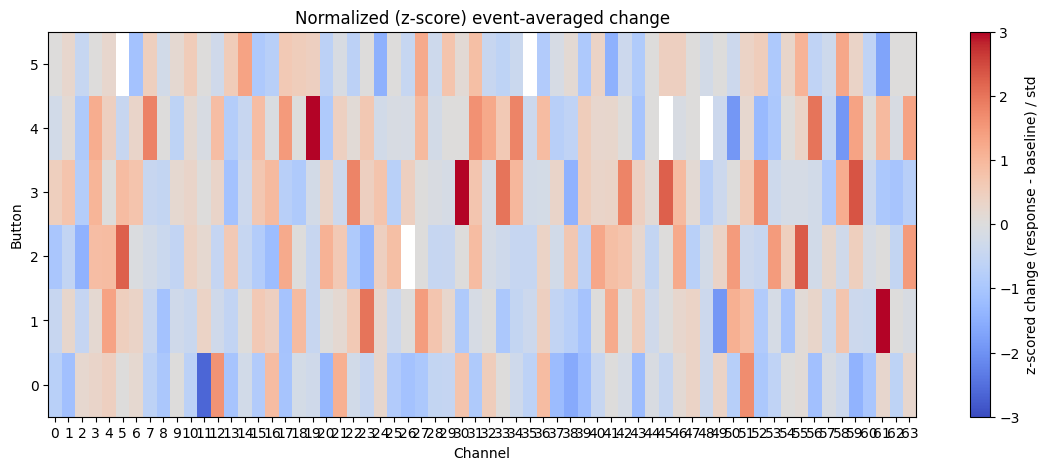

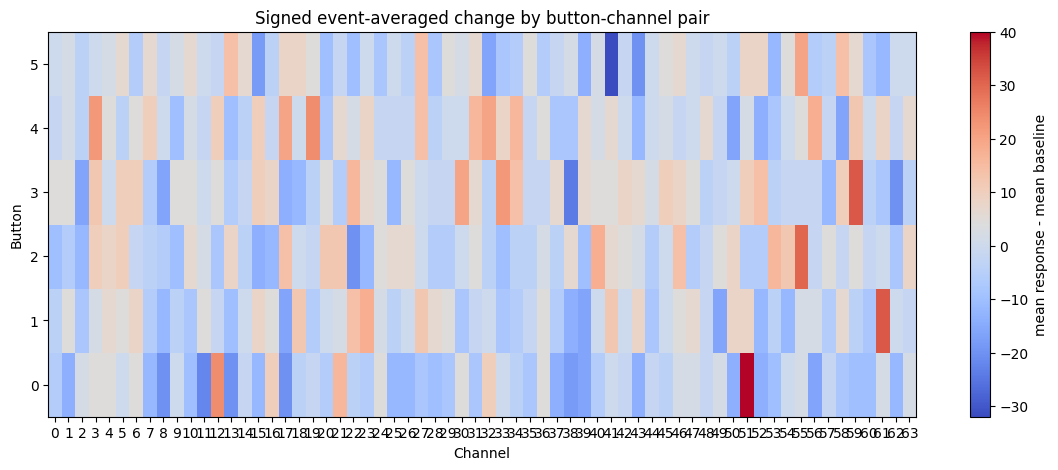

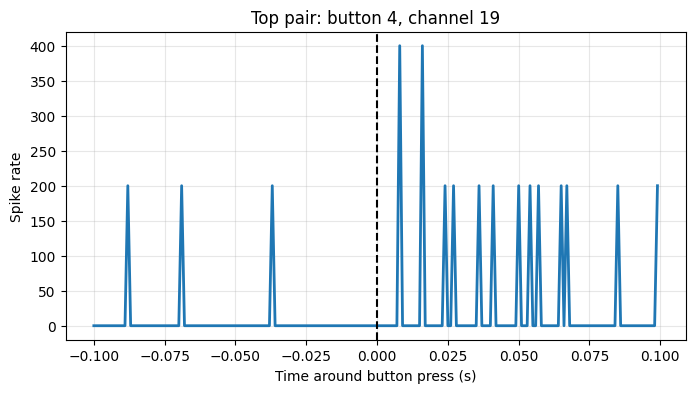

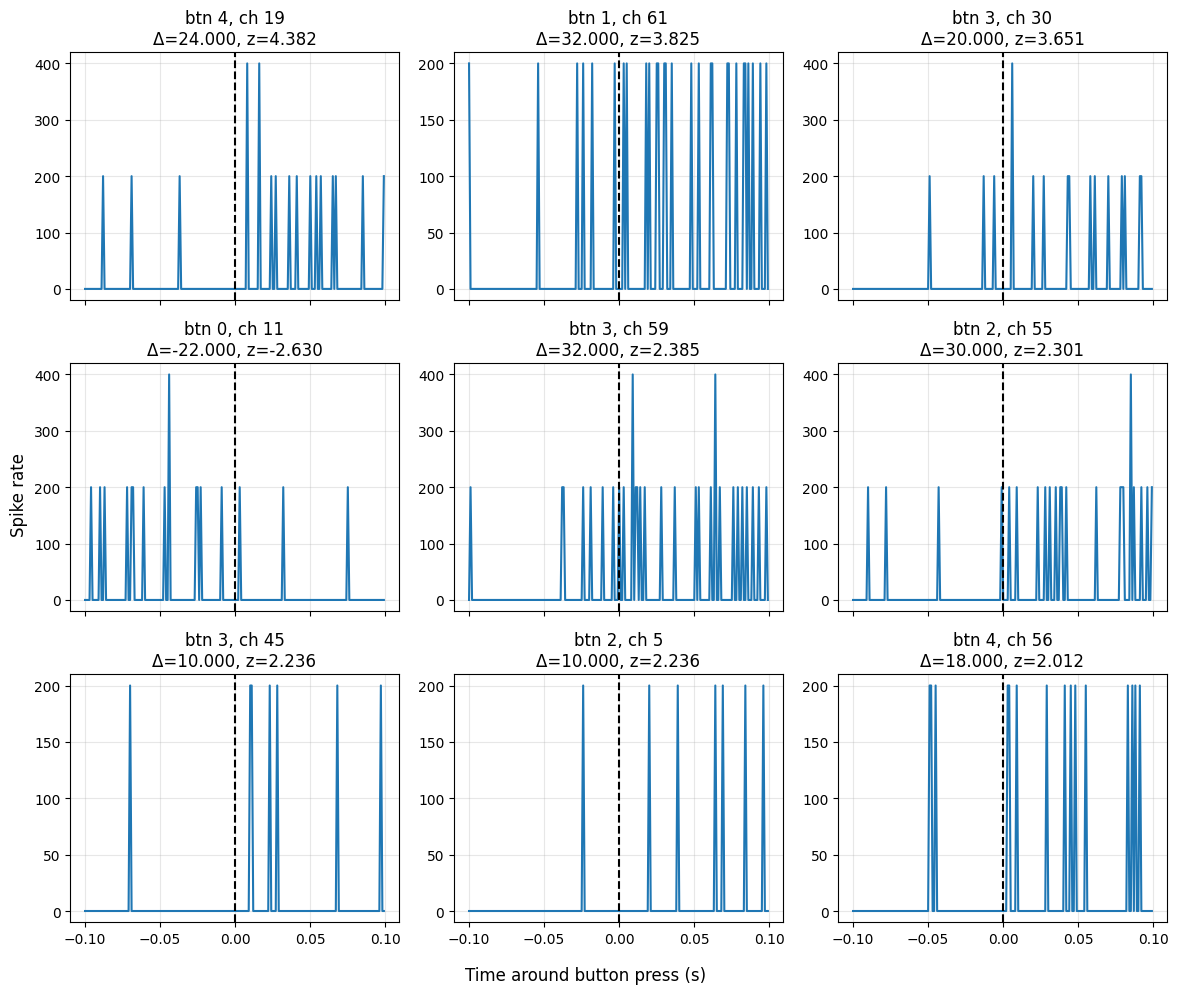

In [141]:
valid_buttons = [0, 1, 2, 3, 4, 5]

# optional safety check
valid_buttons = [
    b for b in valid_buttons
    if b in button_windows_rate and button_windows_rate[b]["windows"].shape[0] > 0
]

print("using buttons:", valid_buttons)

# --------------------------------------------------
# SETTINGS
# --------------------------------------------------
baseline_win = (-0.1, 0.0)
response_win = (0.0, 0.1)

n_channels = rate_mat.shape[1]

# outputs
delta_mat = []
abs_delta_mat = []
z_delta_mat = []
eta_by_button_valid = {}

# --------------------------------------------------
# COMPUTE EVENT-AVERAGED ACTIVITY + CHANGE METRICS
# --------------------------------------------------
for button in valid_buttons:
    wins = button_windows_rate[button]["windows"]   # (n_events, win_len, n_channels)
    rel_t = button_windows_rate[button]["rel_t"]    # (win_len,)

    eta = wins.mean(axis=0)   # (win_len, n_channels)
    eta_by_button_valid[button] = eta

    baseline_mask = (rel_t >= baseline_win[0]) & (rel_t < baseline_win[1])
    response_mask = (rel_t >= response_win[0]) & (rel_t < response_win[1])

    baseline_vals = wins[:, baseline_mask, :].mean(axis=1)   # (n_events, n_channels)
    response_vals = wins[:, response_mask, :].mean(axis=1)   # (n_events, n_channels)

    delta = response_vals.mean(axis=0) - baseline_vals.mean(axis=0)
    abs_delta = np.abs(delta)

    baseline_std = baseline_vals.std(axis=0, ddof=1)
    baseline_std[baseline_std == 0] = np.nan
    z_delta = delta / baseline_std

    delta_mat.append(delta)
    abs_delta_mat.append(abs_delta)
    z_delta_mat.append(z_delta)

delta_mat = np.stack(delta_mat, axis=0)         # (n_valid_buttons, n_channels)
abs_delta_mat = np.stack(abs_delta_mat, axis=0)
z_delta_mat = np.stack(z_delta_mat, axis=0)

button_index_map = {i: b for i, b in enumerate(valid_buttons)}

print("delta_mat shape:", delta_mat.shape)
print("abs_delta_mat shape:", abs_delta_mat.shape)
print("z_delta_mat shape:", z_delta_mat.shape)

# --------------------------------------------------
# RANK BUTTON-CHANNEL PAIRS BY BIGGEST CHANGE
# --------------------------------------------------
score_mat = np.abs(z_delta_mat)

valid_mask = np.isfinite(score_mat)
valid_indices = np.where(valid_mask.ravel())[0]
sorted_valid = valid_indices[np.argsort(score_mat.ravel()[valid_indices])[::-1]]

top_k = min(20, len(sorted_valid))
top_pairs = []

for idx in sorted_valid[:top_k]:
    b_idx, ch = np.unravel_index(idx, score_mat.shape)
    original_button = button_index_map[b_idx]

    top_pairs.append({
        "button": int(original_button),
        "channel": int(ch),
        "delta": float(delta_mat[b_idx, ch]),
        "abs_delta": float(abs_delta_mat[b_idx, ch]),
        "z_delta": float(z_delta_mat[b_idx, ch]) if np.isfinite(z_delta_mat[b_idx, ch]) else np.nan
    })

print("\nTOP BUTTON-CHANNEL PAIRS BY CHANGE")
for i, item in enumerate(top_pairs, 1):
    print(
        f"{i:2d}. button {item['button']}, channel {item['channel']} | "
        f"delta={item['delta']:.4f}, abs_delta={item['abs_delta']:.4f}, z_delta={item['z_delta']:.4f}"
    )

# --------------------------------------------------
# HEATMAP OF CHANGE MAGNITUDE
# --------------------------------------------------
plt.figure(figsize=(14, 5))
plt.imshow(z_delta_mat, aspect='auto', origin='lower', cmap='coolwarm', vmin=-3, vmax=3)
plt.colorbar(label='z-scored change (response - baseline) / std')
plt.xticks(np.arange(n_channels))
plt.yticks(np.arange(len(valid_buttons)), valid_buttons)
plt.xlabel('Channel')
plt.ylabel('Button')
plt.title('Normalized (z-score) event-averaged change')
plt.show()

# --------------------------------------------------
# HEATMAP OF SIGNED CHANGE
# --------------------------------------------------
plt.figure(figsize=(14, 5))
plt.imshow(delta_mat, aspect='auto', origin='lower', cmap='coolwarm')
plt.colorbar(label='mean response - mean baseline')
plt.xticks(np.arange(n_channels))
plt.yticks(np.arange(len(valid_buttons)), valid_buttons)
plt.xlabel('Channel')
plt.ylabel('Button')
plt.title('Signed event-averaged change by button-channel pair')
plt.show()

# --------------------------------------------------
# PLOT TOP PAIR
# --------------------------------------------------
if len(top_pairs) > 0:
    best = top_pairs[0]
    best_button = best["button"]
    best_channel = best["channel"]

    eta = eta_by_button_valid[best_button]
    rel_t = button_windows_rate[best_button]["rel_t"]

    plt.figure(figsize=(8, 4))
    plt.plot(rel_t, eta[:, best_channel], linewidth=2)
    plt.axvline(0, color='k', linestyle='--')
    plt.xlabel("Time around button press (s)")
    plt.ylabel("Spike rate")
    plt.title(f"Top pair: button {best_button}, channel {best_channel}")
    plt.grid(True, alpha=0.3)
    plt.show()

# --------------------------------------------------
# PLOT TOP 9 PAIRS
# --------------------------------------------------
n_plot = min(9, len(top_pairs))
pairs_to_plot = top_pairs[:n_plot]

fig, axes = plt.subplots(3, 3, figsize=(12, 10), sharex=True)
axes = axes.flatten()

for ax, item in zip(axes, pairs_to_plot):
    b = item["button"]
    ch = item["channel"]
    eta = eta_by_button_valid[b]
    rel_t = button_windows_rate[b]["rel_t"]

    ax.plot(rel_t, eta[:, ch])
    ax.axvline(0, color='k', linestyle='--')
    ax.set_title(f"btn {b}, ch {ch}\nΔ={item['delta']:.3f}, z={item['z_delta']:.3f}")
    ax.grid(True, alpha=0.3)

for ax in axes[len(pairs_to_plot):]:
    ax.axis("off")

fig.supxlabel("Time around button press (s)")
fig.supylabel("Spike rate")
plt.tight_layout()
plt.show()

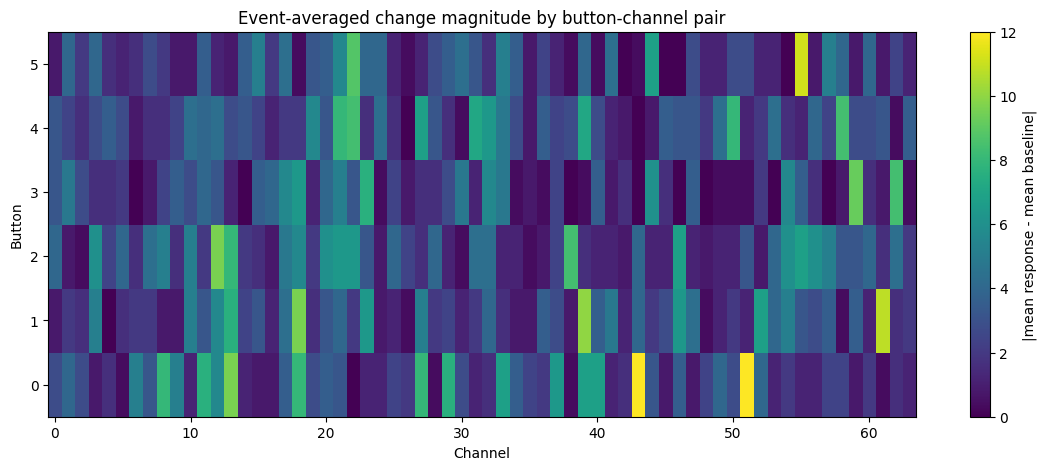

In [117]:
# --------------------------------------------------
# HEATMAP: BIGGEST CHANGE MATRIX
# rows = buttons, cols = channels
# --------------------------------------------------
plt.figure(figsize=(14, 5))
plt.imshow(abs_delta_mat, aspect='auto', origin='lower')
plt.colorbar(label='|mean response - mean baseline|')
plt.xlabel('Channel')
plt.ylabel('Button')
plt.title('Event-averaged change magnitude by button-channel pair')
plt.show()

In [132]:
score_mat = np.abs(z_delta_mat)

valid_mask = np.isfinite(score_mat)
valid_indices = np.where(valid_mask.ravel())[0]
sorted_valid = valid_indices[np.argsort(score_mat.ravel()[valid_indices])[::-1]]

top_k = min(20, len(sorted_valid))
top_pairs = []

for idx in sorted_valid[:top_k]:
    b_idx, ch = np.unravel_index(idx, score_mat.shape)
    original_button = button_index_map[b_idx]

    top_pairs.append({
        "button": int(original_button),
        "channel": int(ch),
        "delta": float(delta_mat[b_idx, ch]),
        "abs_delta": float(abs_delta_mat[b_idx, ch]),
        "z_delta": float(z_delta_mat[b_idx, ch])
    })

print("\nTOP BUTTON-CHANNEL PAIRS BY NORMALIZED CHANGE")
for i, item in enumerate(top_pairs, 1):
    print(
        f"{i:2d}. button {item['button']}, channel {item['channel']} | "
        f"z_delta={item['z_delta']:.4f}, delta={item['delta']:.4f}"
    )


TOP BUTTON-CHANNEL PAIRS BY NORMALIZED CHANGE
 1. button 4, channel 19 | z_delta=5.8138, delta=26.0000
 2. button 3, channel 30 | z_delta=4.0166, delta=22.0000
 3. button 1, channel 49 | z_delta=-4.0166, delta=-22.0000
 4. button 3, channel 59 | z_delta=3.3328, delta=38.0000
 5. button 5, channel 27 | z_delta=2.8284, delta=20.0000
 6. button 4, channel 56 | z_delta=2.6833, delta=24.0000
 7. button 2, channel 5 | z_delta=2.6833, delta=12.0000
 8. button 0, channel 11 | z_delta=-2.6295, delta=-22.0000
 9. button 3, channel 22 | z_delta=2.5560, delta=14.0000
10. button 3, channel 45 | z_delta=2.2361, delta=10.0000
11. button 5, channel 24 | z_delta=-2.2361, delta=-10.0000
12. button 1, channel 51 | z_delta=2.1909, delta=12.0000
13. button 5, channel 29 | z_delta=2.1909, delta=12.0000
14. button 4, channel 52 | z_delta=-2.1514, delta=-18.0000
15. button 4, channel 31 | z_delta=2.0000, delta=20.0000
16. button 1, channel 12 | z_delta=1.9799, delta=14.0000
17. button 4, channel 32 | z_delta